# M08-2 | 從 Q/DQ 圖到 `.pte`：lowering、檔案大小、runtime 執行

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/m08_xnnpack_executorch/02_export_to_pte.ipynb)

M07 的三種處理都還在 PyTorch 裡，沒有產生 int8 kernel。這本 notebook 走路線 A（M07 概覽）：把 Q/DQ 圖交給 ExecuTorch 的 XNNPACK backend，產生部署檔 `.pte`，再用 ExecuTorch runtime 執行。

```text
export（static shape）→ PT2E                 Q/DQ 圖（executorch 版 XNNPACKQuantizer，M08-1）
  → to_edge_transform_and_lower             XnnpackPartitioner 切出子圖，編譯成 delegate
  → to_executorch                           memory planning，序列化成 .pte
  → ExecuTorch runtime                      載入 .pte、執行
```

- **A.** lowering 前後的圖：Q/DQ 圖上的 op 去了哪裡；delegate 裡，XNNPACK 實際執行的 node。
- **B.** `.pte` 的檔案大小：fp32 與 int8。
- **C.** 用 ExecuTorch runtime 執行 `.pte`；換一個 batch 大小會怎樣。

每一步的名詞（Edge dialect、partitioner、delegate、memory planning）在 [M08 概覽](00_overview.ipynb)。這本 notebook 需要 executorch（`uv sync --group executorch`）。

In [1]:
#| include: false
# 在 Google Colab 上執行時：下載本教材的程式並安裝套件（第一次約需幾分鐘）。
# 在自己的電腦上執行時（環境見 README），這一格什麼都不做。
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "executorch==1.5.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # 讓 notebook 能 import 本教材的 common/
    os.chdir(f"{repo}/m08_xnnpack_executorch")

In [2]:
import tempfile
from pathlib import Path

import torch

from common.pt2e import quiet  # 必須在 executorch 之前 import（executorch 會 import torchao）
from common.data import trained_tiny_net
from common.env import capture_stderr, env_summary
from common.executorch_utils import PteRunner, delegation_summary, lower_to_xnnpack, xnnpack_nodes, xnnpack_ptq
from common.graph_utils import op_counts, short
from common.models import example_inputs
from common.viz import draw, table

from executorch.backends.xnnpack.partition.xnnpack_partitioner import XnnpackPartitioner  # noqa: E402
from executorch.exir import to_edge_transform_and_lower  # noqa: E402

quiet()
_ = torch.manual_seed(0)
print(env_summary())

Darwin arm64｜torch 2.14.0｜threads=4｜mkldnn=False｜nnpack=True


## 起點：static shape 的 Q/DQ 圖

模型是 M05 的 `TinyConvNet`（訓練過）。`xnnpack_ptq` 是本專案的包裝（`common/executorch_utils.py`，不是 executorch 的 API），做的是 M01 起熟悉的 PTQ，只有兩處不同：

- `export_module(..., dynamic_batch=False)`：關掉動態 batch，圖只吃 `example_inputs` 的 batch 大小（這裡是 1）。原因在 C 段。
- quantizer 用 executorch 版 `XNNPACKQuantizer`（per-channel weight）。

因為 batch 固定是 1，校準資料也切成一筆一筆餵。

In [3]:
model = trained_tiny_net().eval()
x = example_inputs(1)
qdq = xnnpack_ptq(model, x)  # export（static）→ prepare_pt2e → 校準 → convert_pt2e
counts = op_counts(qdq)
n_before = sum(counts.values())
n_qdq = sum(v for k, v in counts.items() if "quantize" in k)
print(f"Q/DQ 圖：{n_before} 個 call_function，其中 q/dq {n_qdq} 個")

Q/DQ 圖：42 個 call_function，其中 q/dq 28 個


## A. lowering：Q/DQ 圖上的 op 去了哪裡

只用 executorch 的原始 API，分三步：

In [4]:
ep = torch.export.export(qdq, x)                                          # 1. 再 export 一次，得到 ExportedProgram
edge = to_edge_transform_and_lower(ep, partitioner=[XnnpackPartitioner()])  # 2. 轉成 Edge dialect，切 delegate
pte = edge.to_executorch().buffer                                         # 3. memory planning，序列化成 .pte 的 bytes
lowered = edge.exported_program().graph_module                            # 第 2 步之後的圖
print(f"Lowering 之後的 GraphModule：{len(lowered.graph.nodes)} 個 node；.pte {len(pte)} bytes")

Lowering 之後的 GraphModule：5 個 node；.pte 20880 bytes


第 1 步再 export 一次，是因為 `to_edge_transform_and_lower` 吃的是 `ExportedProgram`，而 `convert_pt2e` 回傳的是 GraphModule。這一步也把 shape 依 `x` 寫死。
本專案把這三步包成 `lower_to_xnnpack(gm, example_inputs)`，回傳 `(edge, pte)`，M08-3、M08-4 用它。

第 2 步之後的圖（lowering 之後的 GraphModule）：

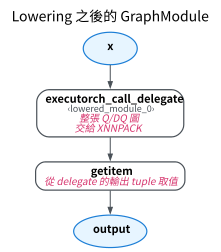

In [5]:
draw(lowered, notes={"executorch_call_delegate": "整張 Q/DQ 圖\n交給 XNNPACK",
                     "getitem": "從 delegate 的輸出 tuple 取值"},
     title="Lowering 之後的 GraphModule")

Q/DQ 圖上的 conv、relu、q/dq 都不見了，只剩一顆 `executorch_call_delegate`。`‹lowered_module_0›` 是它的 delegate：XNNPACK 編譯好的子圖。

哪些 op 進了 delegate？`delegation_summary`（本專案的包裝）呼叫 executorch 的 `get_delegation_info(lowered)`，逐一數每個 op 是交給 XNNPACK、還是留在 ExecuTorch。op 名稱是 Edge dialect 的寫法：

In [6]:
n_sub, n_del, n_non, by_op = delegation_summary(edge)
table([[op, d, nd] for op, (d, nd) in sorted(by_op.items())], ["op（Edge dialect 名稱）", "交給 XNNPACK", "留在 ExecuTorch"])

op（Edge dialect 名稱）,交給 XNNPACK,留在 ExecuTorch
aten_add_tensor,1,0
aten_convolution_default,4,0
aten_linear_default,1,0
aten_max_pool2d_default,2,0
aten_mean_dim,1,0
aten_relu_default,4,0
aten_view_copy_default,1,0
getitem,0,1
quantized_decomposed_dequantize_per_channel_default,5,0
quantized_decomposed_dequantize_per_tensor_default,12,0


In [7]:
left = sorted(op for op, (_, nd) in by_op.items() if nd)
print(f"delegate {n_sub} 個；交給 delegate 的 Edge node {n_del} 個（lowering 前有 {n_before} 個），留下的：{left}")
assert n_sub == 1 and n_del == n_before and left == ["getitem"]

delegate 1 個；交給 delegate 的 Edge node 42 個（lowering 前有 42 個），留下的：['getitem']


- Lowering 前的 op 全部進了同一個 delegate，留下的只有 `getitem`：它是 lowering 時新增的，不是運算。執行時 ExecuTorch 只呼叫 XNNPACK 一次。
- 名稱變了：`conv2d` 在 Edge dialect 已經 decompose 成 `convolution`，`adaptive_avg_pool2d` 變成 `mean`，`flatten` 變成 `view_copy`。
- 上面數的是 Edge node，q/dq 也算在裡面。這些 node 進了 delegate 之後變成什麼，要打開 delegate 才看得到。

### delegate 裡面：XNNPACK 實際執行的 node

`to_edge_transform_and_lower` 把子圖交給 XNNPACK 之後，XNNPACK backend 會把它重建成自己的圖，再序列化進 `.pte`。runtime 執行的是這張圖，不是上面那些 Edge node。

`xnnpack_nodes(qdq, x)` 是本專案的工具（`common/executorch_utils.py`，不是 executorch 的 API）：它再 lower 一次，在 XNNPACK 序列化之前把這張圖攔下來，列出每個 node 的輸入輸出 dtype，以及融合進 node 的輸出範圍（clamp）。它依賴 executorch 1.5.0 的內部結構，換版本可能要改；讀者只需要看懂印出的表。dtype 是 XNNPACK 的寫法：`qint8` 是 per-tensor 的 int8，`qcint8`、`qcint32` 是 per-channel 的 int8 weight、int32 bias。

In [8]:
xnn = xnnpack_nodes(qdq, x)[0]  # 只有一個 delegate
table(xnn, ["XNNPACK node", "輸入 dtype", "輸出 dtype", "輸出 clamp"])

XNNPACK node,輸入 dtype,輸出 dtype,輸出 clamp
XNNConvert,fp32,qint8,
XNNStaticTranspose,qint8,qint8,
XNNConv2d,"qint8, qcint8, qcint32",qint8,"[0, +inf]"
XNNMaxPooling2d,qint8,qint8,
XNNConv2d,"qint8, qcint8, qcint32",qint8,"[0, +inf]"
XNNConv2d,"qint8, qcint8, qcint32",qint8,
XNNAdd,"qint8, qint8",qint8,"[0, +inf]"
XNNMaxPooling2d,qint8,qint8,
XNNConv2d,"qint8, qcint8, qcint32",qint8,"[0, +inf]"
XNNGlobalAvgPooling2d,qint8,qint8,


In [9]:
names = [r[0] for r in xnn]
n_relu = sum(short(n.target) == "relu" for n in qdq.graph.nodes)
n_clamp = sum(r[3] == "[0, +inf]" for r in xnn)
print(f"Q/DQ 圖：{n_before} 個 call_function（q/dq {n_qdq} 個）→ XNNPACK node {len(xnn)} 個")
print(f"XNNConvert {names.count('XNNConvert')} 個；Q/DQ 圖上的 relu {n_relu} 個，融合成 clamp 的 node {n_clamp} 個")

Q/DQ 圖：42 個 call_function（q/dq 28 個）→ XNNPACK node 14 個
XNNConvert 2 個；Q/DQ 圖上的 relu 4 個，融合成 clamp 的 node 4 個


In [10]:
assert names[0] == names[-1] == "XNNConvert" and names.count("XNNConvert") == 2
assert xnn[0][1] == "fp32" and xnn[-1][2] == "fp32" and all(r[2] == "qint8" for r in xnn[:-1])
assert n_clamp == n_relu and not any("Clamp" in n for n in names)

每個 dq → op → q 單元變成一顆 XNNPACK node，輸入輸出都是 `qint8`：

- **q/dq 不見了**：夾在兩個 op 中間的 q/dq 不是運算，只剩 tensor 上的 scale 與 zero point（所以 dtype 是 `qint8`，而不是 fp32）。
- **fp32 ↔ int8 只轉換兩次**：頭尾兩顆 `XNNConvert`，來自圖入口的 q 與出口的 dq。
- **bias 變成 int32**：Q/DQ 圖上的 bias 是 fp32，到這裡是 `qcint32`。
- **relu 融合了**：relu 沒有自己的 node，變成前一個 conv 或 add 的輸出 clamp `[0, +inf]`。
- **多了兩顆 transpose**：XNNPACK 的 conv、pooling 用 NHWC 排列，所以進第一個 conv 前從 NCHW 轉過去，flatten 前再轉回來。Q/DQ 圖上沒有這兩個 op。

這張表就是 [M08 概覽](00_overview.ipynb)〈lowering 時 q/dq 去哪了〉的實例。

## B. `.pte` 的檔案大小：fp32 與 int8

不量化，直接把 fp32 模型 lower，當作對照：

In [11]:
_, pte_fp32 = lower_to_xnnpack(model, x)
n_params = sum(p.numel() for p in model.parameters())
table([["fp32 .pte", len(pte_fp32), n_params * 4], ["int8 .pte", len(pte), n_params]],
      ["", ".pte bytes", "參數全部存成 fp32／int8 的大小"])

,.pte bytes,參數全部存成 fp32／int8 的大小
fp32 .pte,45968,39760
int8 .pte,20880,9940


In [12]:
ratio = len(pte) / len(pte_fp32)
print(f"int8 .pte 是 fp32 .pte 的 {ratio:.0%}（模型共 {n_params} 個參數）")
assert len(pte) < len(pte_fp32)

int8 .pte 是 fp32 .pte 的 45%（模型共 9940 個參數）


- `.pte` 是自包含的部署檔：圖、weight、delegate 的資料、memory plan 都在裡面。
- int8 版的 weight 存成 int8，per-channel 的 scale 另外存；Q/DQ 圖上是 fp32 的 bias，lowering 時被量化成 int32 存進去（M08 概覽）。所以第三個 column 的 int8 估計值（每個參數 1 byte）略低於實際。
- 其餘是圖結構、XNNPACK 子圖的描述、memory plan。這部分不隨參數量成比例變大，模型越大，int8 對 fp32 的比例越接近 1/4（推論，沒有量更大的模型）。

## C. 用 ExecuTorch runtime 執行

部署時交出去的就是 `.pte` 檔。先寫到檔案，再從檔案載入。
`PteRunner` 是本專案的包裝：`executorch.runtime.Runtime.get().load_program(...)` 載入、`load_method("forward")` 取出 method、`execute([...])` 執行（原始 API 在 M08 概覽）。它會一直留著 `load_program` 回傳的 Program：只留 Method、讓 Program 被回收的話，Method 執行時會讀到已釋放的記憶體。

In [13]:
with tempfile.TemporaryDirectory() as d:
    path = Path(d) / "tiny_int8.pte"
    path.write_bytes(pte)
    runner = PteRunner(path)
    y_pte = runner(x[0])
with torch.no_grad():
    y_qdq = qdq(x[0])
out_scale = [n for n in qdq.graph.nodes if short(n.target) == "quantize_per_tensor"][-1].args[1]
print(f"輸入 {tuple(x[0].shape)} → 輸出 {tuple(y_pte.shape)}")
print(f"與 Q/DQ 圖的最大差：{(y_pte - y_qdq).abs().max():.3g}（{(y_pte - y_qdq).abs().max() / out_scale:.2f} 個輸出 LSB）")

輸入 (1, 3, 16, 16) → 輸出 (1, 4)
與 Q/DQ 圖的最大差：0.0643（1.00 個輸出 LSB）


輸出 LSB 是最後一個 quantize 的 scale：int8 的一格。`.pte` 用 XNNPACK 的整數 kernel 算，Q/DQ 圖用 fp32 模擬，兩者不保證逐位元相同（M08 概覽〈和 Q/DQ 圖的數值差異〉）；M08-3 C 段用多筆輸入量差多少。

### 換一個 batch 大小

`.pte` 是用 batch 1 匯出的。餵 batch 4 試試。ExecuTorch runtime 的 C++ 層會把原因印到 stderr，用本專案的 `capture_stderr()`（`common/env.py`）收下來一起印：

In [14]:
with capture_stderr() as log:
    try:
        runner(torch.randn(4, 3, 16, 16))
        error = None
    except RuntimeError as e:
        error = str(e)
print("Python 端：", error)
print("C++ log：")
print(log.text.strip())

Python 端： method->set_inputs() for method 'forward' failed with error 0x10
C++ log：
[tensor_impl.cpp:140] Attempted to resize a static tensor. Expected shape (1, 3, 16, 16), but received (4, 3, 16, 16).
[method.cpp:1246] Error resizing tensor at input 0


In [15]:
assert error is not None and "static tensor" in log.text

`to_executorch()` 依匯出時的 shape 把每個中間 tensor 的記憶體事先規劃好（memory planning），執行時不再配置記憶體。輸入 tensor 的 shape 因此固定，餵不同的 batch 會在 `set_inputs` 這一步就失敗。

這就是 M00 起 `export_module()` 預設開動態 batch（校準時要餵不同 batch 大小）、到了 M08 卻要關掉的原因。ExecuTorch 也支援匯出時給上限的動態 shape（`torch.export.Dim("batch", max=…)`），本專案沒有用。

## 小結

- `to_edge_transform_and_lower` 把 XNNPACK 吃得下的子圖整塊交出去；TinyConvNet 整張圖都進了同一個 delegate。
- delegate 裡，每個 dq → op → q 單元是一顆 int8 的 XNNPACK node，relu 融合成 clamp；fp32 ↔ int8 只在入口、出口轉換。
- `.pte` 自帶圖、int8 weight 與 memory plan，用 ExecuTorch runtime 載入就能執行。
- memory plan 依匯出時的 shape 決定，所以 static shape 匯出的 `.pte` 只吃那個 batch。
- 不支援的 op 會怎樣在 M08-3；有沒有變快在 M08-4。